# M5: четыре LightGBM по неделям горизонта

Вместо одной модели для всех 28 дней обучаем четыре: для горизонтов **1–7, 8–14, 15–21 и 22–28**. Каждая видит все магазины и товары, но только свои семь горизонтов. Затем собираем один прогноз на 28 дней.

Используем нынешние параметры **trial 9**, 67 принятых признаков и тот же полный план дат 52 × 28. На одну модель приходится **52 × 7 × 30 490 = 11 098 360 строк train**. Это четыре отдельных обучения; внутри ноутбука они выполняются последовательно.

Окно разработки — **28 марта — 24 апреля 2016 года**. Число деревьев у каждой модели выбирается отдельно: максимум 1600, early stopping 200 по WRMSSE своей недели. Итоговый WRMSSE считается заново на всех 28 днях.

Сохранённые общие модели и работающая Optuna не меняются. Новые результаты пишутся в отдельную папку и checkpoint. Обучение локально при подготовке ноутбука не выполнялось.

## 1. Запуск на Kaggle

1. Импортировать этот файл в **новый Kaggle Notebook**.
2. Подключить **M5 Forecasting — Accuracy** через Input.
3. Выбрать **CPU / Accelerator → None**. Internet нужен, если потребуется установить LightGBM 4.6.0.
4. Оставить четыре недели в `WEEKS_TO_RUN` и выбрать **Save Version → Save & Run All**.

Старые ноутбуки и checkpoint для первого запуска не нужны. Этот запуск не ждёт завершения Optuna 52 × 28. Одновременные сессии поддерживаются Kaggle; доступность новой сессии определяется лимитами аккаунта и сервиса. Рабочие папки двух ноутбуков независимы.

После каждого готового обучения обновляется **`demand-planner_horizon_weeks_checkpoint.zip`**. Забрать его и выполненный ноутбук из Output сохранённой версии. Для продолжения подключить checkpoint именно этого эксперимента как Input; при нескольких копиях заполнить `RESUME_FROM`.

In [1]:
from pathlib import Path
import importlib.metadata
import os
import subprocess
import sys

if not Path("/kaggle/input").is_dir():
    raise RuntimeError("Этот ноутбук предназначен для Kaggle CPU. Локальное обучение не запускаем.")

PINNED_PACKAGES = {"lightgbm": "4.6.0"}
packages_to_install = []
for package, expected in PINNED_PACKAGES.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != expected:
        if package in sys.modules:
            raise RuntimeError(f"{package} уже импортирован в другой версии; перезапусти kernel.")
        packages_to_install.append(f"{package}=={expected}")
if packages_to_install:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--only-binary=:all:",
            *packages_to_install,
        ],
        check=True,
    )

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"

from contextlib import redirect_stdout
from datetime import datetime, timezone
from functools import lru_cache
from time import perf_counter
from zipfile import ZIP_DEFLATED, ZipFile, is_zipfile
import fcntl
import gc
import gzip
import hashlib
import io
import json
import platform
import shutil

import lightgbm as lgb
import numpy as np
import pandas as pd
import scipy
from IPython.display import FileLink, display

pd.set_option("compute.use_bottleneck", False)
pd.set_option("display.max_columns", 30)
print("LightGBM:", lgb.__version__)
print("Bottleneck:", pd.get_option("compute.use_bottleneck"))

LightGBM: 4.6.0
Bottleneck: False


## 2. Настройки

Все четыре модели используют **одни и те же гиперпараметры прежнего trial 9**. В этом эксперименте меняется разделение по горизонту, новый подбор параметров не проводится. Степень Tweedie также фиксирована.

Для каждой модели выбираем число деревьев по ошибке её семи дней. WRMSSE этой недели использует те же 12 уровней, масштабы и денежные веса, что общий прогноз. Недельные числа нельзя напрямую сравнивать с WRMSSE за 28 дней.

Таймер 11 часов запускается перед подготовкой первого Dataset. Если бюджет исчерпан, незавершённая модель не входит в результат, предыдущие сохраняются. Время проверяется между итерациями; подготовка данных и сохранение файлов могут выйти за срок. При продолжении из checkpoint начинается новый бюджет времени.

In [2]:
SEED = 42
HORIZON = 28
N_ORIGINS = 52
HORIZONS_PER_ORIGIN = 28
NUM_THREADS = 4
MAX_BOOST_ROUNDS = 1600
EARLY_STOPPING_ROUNDS = 200
TIMEOUT_HOURS = 11
RUN_TRAINING = True
WEEKS_TO_RUN = [1, 2, 3, 4]
RESUME_FROM = None

SEARCH_ORIGIN = pd.Timestamp("2016-03-27")
PUBLIC_ORIGIN = pd.Timestamp("2016-04-24")
cb_public_origin = PUBLIC_ORIGIN
RUN_NAME = "lgbm_horizon_weeks_trial9_52x28_v1"
PROJECT_ROOT = Path("/kaggle/working/demand-planner")
RESULT_DIR = PROJECT_ROOT / "results/m5_wrmsse" / RUN_NAME
MODEL_DIR = PROJECT_ROOT / "models" / RUN_NAME
MANIFEST_PATH = RESULT_DIR / "workspace_manifest.json"
CHECKPOINT_PATH = PROJECT_ROOT.parent / "demand-planner_horizon_weeks_checkpoint.zip"

REQUIRED_FILES = ("calendar.csv", "sales_train_validation.csv", "sell_prices.csv")
candidates = sorted(
    {
        path.parent
        for path in Path("/kaggle/input").rglob("calendar.csv")
        if all((path.parent / filename).is_file() for filename in REQUIRED_FILES)
    }
)
if len(candidates) != 1:
    raise FileNotFoundError(
        f"Подключи один набор M5 через Input. Подходящих папок: {len(candidates)}."
    )
DATA_RAW = candidates[0]
if (
    not WEEKS_TO_RUN
    or len(set(WEEKS_TO_RUN)) != len(WEEKS_TO_RUN)
    or not set(WEEKS_TO_RUN).issubset({1, 2, 3, 4})
    or TIMEOUT_HOURS <= 0
):
    raise ValueError("Проверь WEEKS_TO_RUN и TIMEOUT_HOURS.")

WEEK_SPECS = [
    {
        "week": number,
        "name": f"week_{number:02d}",
        "horizon_start": 7 * (number - 1) + 1,
        "horizon_end": 7 * number,
    }
    for number in range(1, 5)
]

FIXED_PARAMS = {
    "objective": "tweedie",
    "metric": "None",
    "boosting_type": "gbdt",
    "device_type": "cpu",
    "num_threads": NUM_THREADS,
    "seed": SEED,
    "deterministic": True,
    "force_col_wise": True,
    "verbosity": -1,
    "max_depth": -1,
    "max_bin": 255,
    "bin_construct_sample_cnt": 200000,
    "feature_pre_filter": False,
    "bagging_freq": 1,
    "min_sum_hessian_in_leaf": 0.001,
    "min_gain_to_split": 0.0,
}
TRIAL9_PARAMS = {
    "learning_rate": 0.09975125819860657,
    "num_leaves": 63,
    "min_data_in_leaf": 250,
    "lambda_l1": 0.8827248013286972,
    "lambda_l2": 1.740351379791848,
    "feature_fraction": 0.8563973660909573,
    "bagging_fraction": 0.7579657376635576,
    "tweedie_variance_power": 1.1026305531889093,
}
MODEL_PARAMS = {**FIXED_PARAMS, **TRIAL9_PARAMS}
BASE_FEATURE_COLUMNS = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
    "mean_7d",
    "mean_28d",
    "mean_56d",
    "std_28d",
    "zero_share_28d",
    "trend_7d_28d",
    "weekday_mean_4w",
    "lag_28d",
    "lag_35d",
    "lag_42d",
    "lag_56d",
    "lag_364d",
    "horizon",
    "day_of_week",
    "day_of_month",
    "month",
    "week_of_year",
    "year",
    "snap",
    "has_event",
    "price_last_known",
    "price_observed_this_week",
    "price_change_1w",
    "price_change_4w",
    "price_vs_mean_4w",
    "price_vs_mean_13w",
    "price_vs_max_13w",
    "price_relative_std_13w",
    "price_observed_share_13w",
    "days_since_last_sale",
    "has_never_sold",
    "sale_day_share_7d",
    "sale_day_share_56d",
    "sale_frequency_change_7d_vs_prev21d",
    "mean_positive_sale_28d",
    "mean_positive_sale_56d",
    "positive_sale_cv2_56d",
    "max_daily_sale_28d",
    "store_dept_mean_7d",
    "store_dept_mean_28d",
    "store_dept_mean_56d",
    "store_dept_trend_7d_28d",
    "store_dept_trend_28d_56d",
    "store_dept_cv_28d",
    "store_dept_weekday_mean_4w",
    "store_dept_weekday_factor_4w",
    "item_share_store_dept_28d",
    "item_share_change_7d_28d",
    "other_stores_mean_7d",
    "other_stores_mean_28d",
    "other_stores_mean_56d",
    "other_stores_trend_7d_28d",
    "other_stores_trend_28d_56d",
    "other_stores_cv_28d",
    "other_stores_weekday_mean_4w",
    "other_stores_weekday_factor_4w",
    "own_vs_other_stores_mean_28d",
    "own_vs_other_stores_trend",
]
TARGET_PRICE_FEATURES = [
    "price_target_week",
    "price_target_vs_last",
    "price_target_vs_mean_13w",
    "price_target_missing",
]
CATEGORICAL_FEATURES = ["item_id", "dept_id", "cat_id", "store_id", "state_id"]
FEATURE_SOURCE_SHA256 = "7f870b6044f91821bf0a28613ba30cadb0503c25f0f07f1b87aa439a4cbae650"
REFERENCE_RESULTS = {
    "single_trial9_52x28": {
        "WRMSSE": 0.5019588456962026,
        "Bias": -0.002901704680924322,
        "trees": 197,
        "source": "notebook 06, " "density28_2016-03-27_52x28_trial_009/protocol.json",
    },
    "ensemble_70_30": {
        "WRMSSE": 0.500879332781371,
        "Bias": -0.005162882802935975,
        "source": "notebook 06, ensemble_pairs_v1; 70% trial9_28 + 30% trial5_8",
    },
}

FEATURE_COLUMNS = [*BASE_FEATURE_COLUMNS, *TARGET_PRICE_FEATURES]
if len(FEATURE_COLUMNS) != 67:
    raise ValueError("Ожидаются 67 принятых признаков.")
print("Эксперимент:", RUN_NAME)
print("Окно:", SEARCH_ORIGIN.date(), "→", (SEARCH_ORIGIN + pd.Timedelta(days=HORIZON)).date())
print("Признаков:", len(FEATURE_COLUMNS), "| Bottleneck:", pd.get_option("compute.use_bottleneck"))
print("План: четыре последовательных обучения, по 11 098 360 строк каждое.")
display(pd.DataFrame(WEEK_SPECS))

Эксперимент: lgbm_horizon_weeks_trial9_52x28_v1
Окно: 2016-03-27 → 2016-04-24
Признаков: 67 | Bottleneck: False
План: четыре последовательных обучения, по 11 098 360 строк каждое.


,week,name,horizon_start,horizon_end
0,1,week_01,1,7
1,2,week_02,8,14
2,3,week_03,15,21
3,4,week_04,22,28


## 3. История и иерархия M5

Читаем 30 490 рядов. Все обучающие цели заканчиваются 27 марта. Факты последующих 28 дней используются для ранней остановки и оценки на историческом окне разработки.

Масштабы RMSSE и денежные веса вычисляются на истории до даты прогноза один раз. Эти же веса применяются ко всем четырём неделям и к итоговому прогнозу. Код полной WRMSSE сохранён из ноутбука 07.

In [3]:
calendar = pd.read_csv(DATA_RAW / "calendar.csv", parse_dates=["date"])
if calendar["date"].duplicated().any() or calendar["d"].duplicated().any():
    raise ValueError("В календаре есть повторяющиеся дни.")

In [4]:
identifier_columns = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]

series_metadata = pd.read_csv(
    DATA_RAW / "sales_train_validation.csv",
    usecols=identifier_columns,
    dtype="string",
)

assert not series_metadata.duplicated(["item_id", "store_id"]).any()
assert len(series_metadata) == 30_490
assert series_metadata["store_id"].nunique() == 10

M5_LEVELS = {
    "Total": [],
    "State": ["state_id"],
    "Store": ["store_id"],
    "Category": ["cat_id"],
    "Department": ["dept_id"],
    "State / Category": ["state_id", "cat_id"],
    "State / Department": ["state_id", "dept_id"],
    "Store / Category": ["store_id", "cat_id"],
    "Store / Department": ["store_id", "dept_id"],
    "Item": ["item_id"],
    "Item / State": ["item_id", "state_id"],
    "Item / Store": ["item_id", "store_id"],
}

hierarchy = pd.DataFrame(
    [
        {
            "level": level,
            "series": (series_metadata.groupby(columns, observed=True).ngroups if columns else 1),
        }
        for level, columns in M5_LEVELS.items()
    ]
).set_index("level")

assert int(hierarchy["series"].sum()) == 42_840
display(hierarchy)
print(f"Всего оцениваемых рядов: {hierarchy['series'].sum():,}")

,series
level,
Total,1
State,3
Store,10
Category,3
Department,7
State / Category,9
State / Department,21
Store / Category,30
Store / Department,70


Всего оцениваемых рядов: 42,840


In [5]:
M5_KEYS = ["store_id", "item_id"]
TRAIN_END_DAY = 1913

train_day_columns = [f"d_{day}" for day in range(1, TRAIN_END_DAY + 1)]

series_index = pd.MultiIndex.from_frame(series_metadata[M5_KEYS])

train_daily = pd.read_csv(
    DATA_RAW / "sales_train_validation.csv",
    usecols=[*M5_KEYS, *train_day_columns],
    dtype={
        "store_id": "string",
        "item_id": "string",
        **{column: "int32" for column in train_day_columns},
    },
)

train_daily = train_daily.set_index(M5_KEYS).reindex(series_index).loc[:, train_day_columns]

train_daily.columns = pd.DatetimeIndex(
    calendar.set_index("d").loc[train_day_columns, "date"],
    name="date",
)

weight_dates = train_daily.loc[:, :SEARCH_ORIGIN].columns[-28:]

weight_weeks = calendar.set_index("date").loc[weight_dates, "wm_yr_wk"].unique()

price_parts = []

for chunk in pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    usecols=["store_id", "item_id", "wm_yr_wk", "sell_price"],
    dtype={
        "store_id": "string",
        "item_id": "string",
        "wm_yr_wk": "int32",
        "sell_price": "float64",
    },
    chunksize=200_000,
):
    selected = chunk.loc[chunk["wm_yr_wk"].isin(weight_weeks)]

    if not selected.empty:
        price_parts.append(selected.copy())

prices_for_weights = pd.concat(
    price_parts,
    ignore_index=True,
)

del price_parts

print(f"Рядов: {len(train_daily):,}")
print(f"Дней истории: {train_daily.shape[1]:,}")
print(
    "Период для весов:",
    weight_dates.min().date(),
    "—",
    weight_dates.max().date(),
)

Рядов: 30,490
Дней истории: 1,913
Период для весов: 2016-02-29 — 2016-03-27


In [6]:
from scipy.sparse import csr_matrix


def calculate_rmsse_scale(history_values, aggregation, block_size=128):
    n_groups = aggregation.shape[0]
    n_days = history_values.shape[1]

    first_nonzero = np.full(n_groups, n_days, dtype=np.int32)
    squared_difference_sum = np.zeros(n_groups, dtype=np.float64)
    previous = np.zeros(n_groups, dtype=np.float64)

    for start in range(0, n_days, block_size):
        stop = min(start + block_size, n_days)

        block = np.asarray(
            aggregation @ history_values[:, start:stop],
            dtype=np.float64,
        )

        positive = block > 0
        newly_active = (first_nonzero == n_days) & positive.any(axis=1)

        if newly_active.any():
            first_nonzero[newly_active] = start + positive[newly_active].argmax(axis=1)

        differences = np.empty_like(block)
        differences[:, 0] = block[:, 0] - previous
        differences[:, 1:] = np.diff(block, axis=1)

        positions = np.arange(start, stop)
        exclude = positions[None, :] <= first_nonzero[:, None]
        differences[exclude] = 0.0

        squared_difference_sum += np.einsum(
            "ij,ij->i",
            differences,
            differences,
        )

        previous = block[:, -1].copy()

    difference_count = n_days - first_nonzero - 1

    return np.divide(
        squared_difference_sum,
        difference_count,
        out=np.zeros(n_groups, dtype=np.float64),
        where=difference_count > 0,
    )


class M5WRMSSE:
    def __init__(
        self,
        history,
        metadata,
        calendar,
        prices,
        levels,
        horizon=28,
    ):
        if len(metadata) != 30_490 or len(levels) != 12:
            raise ValueError("Для полного M5 нужны 30 490 рядов и 12 уровней.")

        self.series_index = pd.MultiIndex.from_frame(metadata[M5_KEYS])

        if (
            self.series_index.has_duplicates
            or history.index.has_duplicates
            or len(history) != len(self.series_index)
            or not self.series_index.isin(history.index).all()
        ):
            raise ValueError("Идентификаторы истории и metadata не совпадают.")

        history = history.reindex(self.series_index)

        if history.shape[1] < 28:
            raise ValueError("Для расчёта весов нужны минимум 28 дней.")

        if not isinstance(history.columns, pd.DatetimeIndex):
            raise TypeError("Столбцы истории должны содержать даты.")

        expected_history_dates = pd.date_range(
            history.columns[0],
            periods=history.shape[1],
            freq="D",
        )

        if not history.columns.equals(expected_history_dates):
            raise ValueError("В истории есть пропуски или нарушен порядок дней.")

        history_values = history.to_numpy(copy=False)

        if not np.isfinite(history_values).all() or (history_values < 0).any():
            raise ValueError("История должна содержать конечные неотрицательные продажи.")

        self.horizon = horizon
        self.n_levels = len(levels)
        self.forecast_dates = pd.date_range(
            history.columns[-1] + pd.Timedelta(days=1),
            periods=horizon,
            freq="D",
            name="date",
        )

        recent_dates = history.columns[-28:]

        week_codes = calendar.set_index("date").reindex(recent_dates)["wm_yr_wk"].to_numpy()

        if pd.isna(week_codes).any():
            raise ValueError("В календаре отсутствуют даты для расчёта весов.")

        known_prices = prices["sell_price"].dropna().to_numpy()

        if not np.isfinite(known_prices).all() or (known_prices <= 0).any():
            raise ValueError("Известные цены должны быть конечными и положительными.")

        price_table = prices.pivot(
            index=M5_KEYS,
            columns="wm_yr_wk",
            values="sell_price",
        )

        daily_prices = price_table.reindex(
            index=self.series_index,
            columns=week_codes,
        ).to_numpy(dtype=np.float64)

        recent_units = history.iloc[:, -28:].to_numpy(dtype=np.float64)

        missing_price_with_sales = (recent_units > 0) & ~np.isfinite(daily_prices)

        if missing_price_with_sales.any():
            raise ValueError(
                "Есть положительные продажи без цены: веса нельзя посчитать корректно."
            )

        dollar_sales = (recent_units * np.nan_to_num(daily_prices, nan=0.0)).sum(axis=1)

        total_dollar_sales = dollar_sales.sum()

        if total_dollar_sales <= 0:
            raise ValueError("Суммарные денежные продажи равны нулю.")

        metadata = metadata.reset_index(drop=True)

        self.level_specs = {}
        level_rows = []

        for level_name, columns in levels.items():
            if columns:
                group_index = pd.MultiIndex.from_frame(metadata[columns])
                codes, groups = pd.factorize(
                    group_index,
                    sort=True,
                )
                n_groups = len(groups)
            else:
                codes = np.zeros(len(metadata), dtype=np.int32)
                n_groups = 1

            aggregation = csr_matrix(
                (
                    np.ones(len(metadata), dtype=np.float64),
                    (codes, np.arange(len(metadata))),
                ),
                shape=(n_groups, len(metadata)),
            )

            print(f"Масштабы: {level_name} — {n_groups:,} рядов")

            scale = calculate_rmsse_scale(
                history_values,
                aggregation,
            )

            group_dollar_sales = np.asarray(aggregation @ dollar_sales).ravel()

            weights = group_dollar_sales / total_dollar_sales / self.n_levels

            if ((scale <= 0) & (weights > 0)).any():
                raise ValueError(
                    f"{level_name}: есть ряд с положительным весом " "и нулевым масштабом RMSSE."
                )

            self.level_specs[level_name] = {
                "aggregation": aggregation,
                "scale": scale,
                "weights": weights,
            }

            level_rows.append(
                {
                    "level": level_name,
                    "series": n_groups,
                    "weight_sum": weights.sum(),
                }
            )

        self.level_info = pd.DataFrame(level_rows).set_index("level")

        if self.level_info["series"].sum() != 42_840:
            raise ValueError("Получено неверное число рядов иерархии.")

        if not np.isclose(self.level_info["weight_sum"].sum(), 1.0):
            raise ValueError("Сумма весов WRMSSE отличается от единицы.")

    def _aligned_values(self, frame):
        if not isinstance(frame, pd.DataFrame):
            raise TypeError("Передай DataFrame с идентификаторами и датами.")

        if (
            frame.index.has_duplicates
            or len(frame) != len(self.series_index)
            or not self.series_index.isin(frame.index).all()
        ):
            raise ValueError("Набор товаров и магазинов не совпадает.")

        if not frame.columns.equals(self.forecast_dates):
            raise ValueError("Столбцы должны содержать следующие 28 дат " "в правильном порядке.")

        values = frame.reindex(self.series_index).to_numpy(dtype=np.float64)

        if not np.isfinite(values).all():
            raise ValueError("В фактах или прогнозах есть NaN либо бесконечность.")

        return values

    def score(self, actual, prediction):
        actual_values = self._aligned_values(actual)
        prediction_values = self._aligned_values(prediction)

        bottom_errors = prediction_values - actual_values
        rows = []

        for level_name, spec in self.level_specs.items():
            aggregated_errors = spec["aggregation"] @ bottom_errors

            mse = np.mean(
                np.square(aggregated_errors),
                axis=1,
            )

            rmsse = np.sqrt(
                np.divide(
                    mse,
                    spec["scale"],
                    out=np.zeros_like(mse),
                    where=spec["scale"] > 0,
                )
            )

            contribution = float(np.dot(spec["weights"], rmsse))

            rows.append(
                {
                    "level": level_name,
                    "weighted_RMSSE": contribution * self.n_levels,
                    "contribution": contribution,
                }
            )

        report = pd.DataFrame(rows).set_index("level")
        overall = float(report["contribution"].sum())

        return overall, report

In [7]:
wrmsse_evaluator = M5WRMSSE(
    history=train_daily.loc[:, :SEARCH_ORIGIN],
    metadata=series_metadata,
    calendar=calendar,
    prices=prices_for_weights,
    levels=M5_LEVELS,
    horizon=HORIZON,
)

display(
    wrmsse_evaluator.level_info.style.format(
        {
            "series": "{:,.0f}",
            "weight_sum": "{:.6f}",
        }
    )
)

print(
    "Всего рядов:",
    f"{wrmsse_evaluator.level_info['series'].sum():,}",
)

print(
    "Сумма весов:",
    f"{wrmsse_evaluator.level_info['weight_sum'].sum():.6f}",
)

print(
    "Даты будущего прогноза:",
    wrmsse_evaluator.forecast_dates.min().date(),
    "—",
    wrmsse_evaluator.forecast_dates.max().date(),
)

Масштабы: Total — 1 рядов
Масштабы: State — 3 рядов
Масштабы: Store — 10 рядов
Масштабы: Category — 3 рядов
Масштабы: Department — 7 рядов
Масштабы: State / Category — 9 рядов
Масштабы: State / Department — 21 рядов
Масштабы: Store / Category — 30 рядов
Масштабы: Store / Department — 70 рядов
Масштабы: Item — 3,049 рядов
Масштабы: Item / State — 9,147 рядов
Масштабы: Item / Store — 30,490 рядов


,series,weight_sum
level,,
Total,1,0.083333
State,3,0.083333
Store,10,0.083333
Category,3,0.083333
Department,7,0.083333
State / Category,9,0.083333
State / Department,21,0.083333
Store / Category,30,0.083333
Store / Department,70,0.083333


Всего рядов: 42,840
Сумма весов: 1.000000
Даты будущего прогноза: 2016-03-28 — 2016-04-24


In [8]:
def price_evaluate(evaluator, actual, prediction):
    score, report = evaluator.score(actual, prediction)
    actual_total = (
        actual.reindex(index=prediction.index, columns=prediction.columns)
        .to_numpy(dtype=np.float64)
        .sum()
    )
    metrics = {
        "WRMSSE": float(score),
        "Bias": float(prediction.to_numpy().sum() / actual_total - 1),
    }
    return (metrics, report)

## 4. Те же 67 признаков

История продаж и цены, календарь, регулярность продаж, динамика отдела, продажи того же товара в остальных магазинах и цена целевой недели. EWMA и лаги 7/14/21 день сюда не добавляются.

Для каждой обучающей пары признаки продаж ограничиваются её датой отсчёта. Цена целевой недели и календарь используются как известные будущие факторы в постановке M5. Категории и порядок столбцов едины для всех моделей.

In [9]:
daily_categorical_features = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
]

daily_history = train_daily.reindex(wrmsse_evaluator.series_index)

daily_history_dates = daily_history.columns
daily_history_values = daily_history.to_numpy(copy=False)

daily_identifiers = (
    series_metadata.set_index(M5_KEYS)
    .loc[wrmsse_evaluator.series_index]
    .reset_index()
    .loc[:, daily_categorical_features]
)

daily_identifiers.index = wrmsse_evaluator.series_index

for column in daily_categorical_features:
    daily_identifiers[column] = daily_identifiers[column].astype("category")

daily_calendar = calendar.set_index("date")


def make_daily_features(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)

    horizon = (target_date - forecast_origin).days

    if not 1 <= horizon <= HORIZON:
        raise ValueError("Горизонт должен быть от 1 до 28 дней.")

    origin_position = daily_history_dates.get_indexer([forecast_origin])[0]

    if origin_position < 55:
        raise ValueError(
            "Дата прогноза должна присутствовать в истории " "и иметь минимум 56 доступных дней."
        )

    X = daily_identifiers.copy()
    known_history = daily_history_values[:, : origin_position + 1]

    for window in (7, 28, 56):
        X[f"mean_{window}d"] = known_history[:, -window:].mean(axis=1).astype("float32")

    recent_28 = known_history[:, -28:]

    X["std_28d"] = recent_28.std(axis=1, ddof=1).astype("float32")

    X["zero_share_28d"] = (recent_28 == 0).mean(axis=1).astype("float32")

    X["trend_7d_28d"] = (X["mean_7d"] - X["mean_28d"]).astype("float32")

    recent_dates = daily_history_dates[origin_position - 27 : origin_position + 1]

    weekday_mask = recent_dates.dayofweek == target_date.dayofweek

    X["weekday_mean_4w"] = recent_28[:, weekday_mask].mean(axis=1).astype("float32")

    for lag in (28, 35, 42, 56, 364):
        source_date = target_date - pd.Timedelta(days=lag)

        if source_date > forecast_origin:
            raise ValueError("Лаг обращается к неизвестному будущему.")

        source_position = daily_history_dates.get_indexer([source_date])[0]

        if source_position >= 0:
            X[f"lag_{lag}d"] = daily_history_values[:, source_position].astype("float32")
        else:
            X[f"lag_{lag}d"] = np.float32(np.nan)

    calendar_values = daily_calendar.loc[target_date]

    target_features = {
        "horizon": horizon,
        "day_of_week": target_date.dayofweek,
        "day_of_month": target_date.day,
        "month": target_date.month,
        "week_of_year": int(target_date.isocalendar().week),
        "year": target_date.year,
    }

    for name, value in target_features.items():
        X[name] = np.int16(value)

    snap_by_state = {state: int(calendar_values[f"snap_{state}"]) for state in ("CA", "TX", "WI")}

    X["snap"] = X["state_id"].map(snap_by_state).astype("int8")

    X["has_event"] = np.int8(
        pd.notna(calendar_values["event_name_1"]) or pd.notna(calendar_values["event_name_2"])
    )

    return X

In [10]:
price_data = pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float64",
    },
)
price_week_starts = calendar.groupby("wm_yr_wk")["date"].min().sort_values()
price_week_order = price_week_starts.loc[price_week_starts <= cb_public_origin].index
price_data = price_data.loc[price_data["wm_yr_wk"].isin(price_week_order)].copy()
price_week_table = (
    price_data.pivot(index=M5_KEYS, columns="wm_yr_wk", values="sell_price")
    .reindex(index=wrmsse_evaluator.series_index, columns=price_week_order)
    .astype("float32")
)
price_last_known_table = price_week_table.ffill(axis=1)


@lru_cache(maxsize=64)
def price_features_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)
    week = int(daily_calendar.loc[forecast_origin, "wm_yr_wk"])
    position = price_week_table.columns.get_loc(week)
    if position < 12:
        raise ValueError("Для признаков цены нужны 13 недель истории.")
    recent_4 = price_week_table.iloc[:, position - 3 : position + 1]
    recent_13 = price_week_table.iloc[:, position - 12 : position + 1]
    current = price_last_known_table.iloc[:, position]
    previous_1 = price_last_known_table.iloc[:, position - 1]
    previous_4 = price_last_known_table.iloc[:, position - 4]
    mean_4 = recent_4.mean(axis=1)
    mean_13 = recent_13.mean(axis=1)
    return pd.DataFrame(
        {
            "price_last_known": current,
            "price_observed_this_week": price_week_table.iloc[:, position].notna(),
            "price_change_1w": current / previous_1 - 1,
            "price_change_4w": current / previous_4 - 1,
            "price_vs_mean_4w": current / mean_4 - 1,
            "price_vs_mean_13w": current / mean_13 - 1,
            "price_vs_max_13w": current / recent_13.max(axis=1) - 1,
            "price_relative_std_13w": recent_13.std(axis=1, ddof=0) / mean_13,
            "price_observed_share_13w": recent_13.notna().mean(axis=1),
        }
    ).astype("float32")


def make_daily_features_with_price(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    base = make_daily_features(forecast_origin=forecast_origin, target_date=target_date)
    return base.join(price_features_at_origin(forecast_origin), validate="one_to_one")

In [11]:
@lru_cache(maxsize=64)
def regularity_features_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)
    position = daily_history_dates.get_indexer([forecast_origin])[0]
    if position < 55:
        raise ValueError("Дата должна присутствовать в истории и иметь минимум 56 доступных дней.")
    known = daily_history_values[:, : position + 1]
    positive_history = known > 0
    has_ever_sold = positive_history.any(axis=1)
    days_since_sale = positive_history[:, ::-1].argmax(axis=1).astype("float32")
    days_since_sale[~has_ever_sold] = np.nan
    recent_56 = known[:, -56:].astype("float64")
    recent_28 = recent_56[:, -28:]
    positive_56 = positive_history[:, -56:]
    positive_28 = positive_56[:, -28:]
    count_56 = positive_56.sum(axis=1)
    count_28 = positive_28.sum(axis=1)
    sum_56 = recent_56.sum(axis=1)
    sum_28 = recent_28.sum(axis=1)
    mean_positive_56 = np.divide(
        sum_56, count_56, out=np.full(len(known), np.nan), where=count_56 > 0
    )
    mean_positive_28 = np.divide(
        sum_28, count_28, out=np.full(len(known), np.nan), where=count_28 > 0
    )
    squared_sum_56 = np.einsum("ij,ij->i", recent_56, recent_56)
    correction = np.divide(
        np.square(sum_56), count_56, out=np.zeros(len(known)), where=count_56 > 0
    )
    positive_variance_56 = np.divide(
        np.maximum(squared_sum_56 - correction, 0.0),
        count_56 - 1,
        out=np.full(len(known), np.nan),
        where=count_56 > 1,
    )
    positive_cv2_56 = np.divide(
        positive_variance_56,
        np.square(mean_positive_56),
        out=np.full(len(known), np.nan),
        where=count_56 > 1,
    )
    frequency_7 = positive_56[:, -7:].mean(axis=1)
    frequency_previous_21 = positive_56[:, -28:-7].mean(axis=1)
    return pd.DataFrame(
        {
            "days_since_last_sale": days_since_sale,
            "has_never_sold": ~has_ever_sold,
            "sale_day_share_7d": frequency_7,
            "sale_day_share_56d": positive_56.mean(axis=1),
            "sale_frequency_change_7d_vs_prev21d": frequency_7 - frequency_previous_21,
            "mean_positive_sale_28d": mean_positive_28,
            "mean_positive_sale_56d": mean_positive_56,
            "positive_sale_cv2_56d": positive_cv2_56,
            "max_daily_sale_28d": recent_28.max(axis=1),
        },
        index=wrmsse_evaluator.series_index,
    ).astype("float32")


def make_daily_features_with_regularity(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    X = make_daily_features_with_price(forecast_origin, target_date)
    return X.join(regularity_features_at_origin(forecast_origin), validate="one_to_one")

In [12]:
group_aggregation = wrmsse_evaluator.level_specs["Store / Department"]["aggregation"]
group_membership = group_aggregation.tocoo()
group_codes = np.empty(len(wrmsse_evaluator.series_index), dtype=np.int32)
group_codes[group_membership.col] = group_membership.row
group_daily_sales = np.asarray(group_aggregation @ daily_history_values, dtype=np.float64)


def group_safe_ratio(numerator, denominator):
    numerator = np.asarray(numerator, dtype=np.float64)
    denominator = np.asarray(denominator, dtype=np.float64)
    return np.divide(
        numerator,
        denominator,
        out=np.full(numerator.shape, np.nan),
        where=denominator > 0,
    )


@lru_cache(maxsize=64)
def group_statistics_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)
    position = daily_history_dates.get_indexer([forecast_origin])[0]
    if position < 55:
        raise ValueError("Для групповых признаков нужны 56 доступных дней.")
    known = group_daily_sales[:, : position + 1]
    recent_28 = known[:, -28:]
    recent_dates = daily_history_dates[position - 27 : position + 1]
    statistics = {f"mean_{window}d": known[:, -window:].mean(axis=1) for window in (7, 28, 56)}
    statistics["std_28d"] = recent_28.std(axis=1, ddof=1)
    statistics["weekday_mean_4w"] = np.column_stack(
        [recent_28[:, recent_dates.dayofweek == weekday].mean(axis=1) for weekday in range(7)]
    )
    return statistics


def make_daily_features_with_groups(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)
    X = make_daily_features_with_regularity(forecast_origin, target_date)
    statistics = group_statistics_at_origin(forecast_origin)
    mean_7 = statistics["mean_7d"][group_codes]
    mean_28 = statistics["mean_28d"][group_codes]
    mean_56 = statistics["mean_56d"][group_codes]
    weekday_mean = statistics["weekday_mean_4w"][group_codes, target_date.dayofweek]
    item_share_7 = group_safe_ratio(X["mean_7d"].to_numpy(), mean_7)
    item_share_28 = group_safe_ratio(X["mean_28d"].to_numpy(), mean_28)
    added_features = {
        "store_dept_mean_7d": mean_7,
        "store_dept_mean_28d": mean_28,
        "store_dept_mean_56d": mean_56,
        "store_dept_trend_7d_28d": group_safe_ratio(mean_7, mean_28) - 1,
        "store_dept_trend_28d_56d": group_safe_ratio(mean_28, mean_56) - 1,
        "store_dept_cv_28d": group_safe_ratio(statistics["std_28d"][group_codes], mean_28),
        "store_dept_weekday_mean_4w": weekday_mean,
        "store_dept_weekday_factor_4w": group_safe_ratio(weekday_mean, mean_28),
        "item_share_store_dept_28d": item_share_28,
        "item_share_change_7d_28d": item_share_7 - item_share_28,
    }
    for column, values in added_features.items():
        X[column] = values.astype("float32")
    return X

In [13]:
cross_store_aggregation = wrmsse_evaluator.level_specs["Item"]["aggregation"]
cross_store_membership = cross_store_aggregation.tocoo()
cross_store_codes = np.empty(len(wrmsse_evaluator.series_index), dtype=np.int32)
cross_store_codes[cross_store_membership.col] = cross_store_membership.row
cross_store_counts = np.asarray(cross_store_aggregation.sum(axis=1)).ravel()
cross_store_other_counts = cross_store_counts[cross_store_codes] - 1
cross_store_daily_totals = np.asarray(
    cross_store_aggregation @ daily_history_values, dtype=np.float64
)


@lru_cache(maxsize=64)
def cross_store_statistics_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)
    position = daily_history_dates.get_indexer([forecast_origin])[0]
    if position < 55:
        raise ValueError("Для признаков других магазинов нужны 56 дней истории.")
    start = position - 55
    network_sales = cross_store_daily_totals[cross_store_codes, start : position + 1]
    own_sales = daily_history_values[:, start : position + 1]
    other_sales = (network_sales - own_sales) / cross_store_other_counts[:, None]
    recent_28 = other_sales[:, -28:]
    recent_dates = daily_history_dates[position - 27 : position + 1]
    statistics = {
        f"mean_{window}d": other_sales[:, -window:].mean(axis=1).astype("float32")
        for window in (7, 28, 56)
    }
    statistics["std_28d"] = recent_28.std(axis=1, ddof=1).astype("float32")
    statistics["weekday_mean_4w"] = np.column_stack(
        [recent_28[:, recent_dates.dayofweek == weekday].mean(axis=1) for weekday in range(7)]
    ).astype("float32")
    return statistics


def make_daily_features_with_cross_store(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)
    X = make_daily_features_with_groups(forecast_origin, target_date)
    statistics = cross_store_statistics_at_origin(forecast_origin)
    mean_7 = statistics["mean_7d"]
    mean_28 = statistics["mean_28d"]
    mean_56 = statistics["mean_56d"]
    weekday_mean = statistics["weekday_mean_4w"][:, target_date.dayofweek]
    own_trend = group_safe_ratio(X["mean_7d"].to_numpy(), X["mean_28d"].to_numpy()) - 1
    other_trend = group_safe_ratio(mean_7, mean_28) - 1
    added_features = {
        "other_stores_mean_7d": mean_7,
        "other_stores_mean_28d": mean_28,
        "other_stores_mean_56d": mean_56,
        "other_stores_trend_7d_28d": other_trend,
        "other_stores_trend_28d_56d": group_safe_ratio(mean_28, mean_56) - 1,
        "other_stores_cv_28d": group_safe_ratio(statistics["std_28d"], mean_28),
        "other_stores_weekday_mean_4w": weekday_mean,
        "other_stores_weekday_factor_4w": group_safe_ratio(weekday_mean, mean_28),
        "own_vs_other_stores_mean_28d": group_safe_ratio(X["mean_28d"].to_numpy(), mean_28),
        "own_vs_other_stores_trend": own_trend - other_trend,
    }
    for column, values in added_features.items():
        X[column] = values.astype("float32")
    return X

In [14]:
CATEGORY_TYPES = {
    column: pd.CategoricalDtype(
        categories=daily_identifiers[column].cat.categories,
        ordered=False,
    )
    for column in CATEGORICAL_FEATURES
}

target_price_source = pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    usecols=["store_id", "item_id", "wm_yr_wk", "sell_price"],
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float32",
    },
)
observed_prices = target_price_source["sell_price"].dropna().to_numpy()
if not np.isfinite(observed_prices).all() or (observed_prices <= 0).any():
    raise ValueError("Некорректные наблюдаемые цены.")
target_week_prices = (
    target_price_source.pivot(index=M5_KEYS, columns="wm_yr_wk", values="sell_price")
    .reindex(index=wrmsse_evaluator.series_index)
    .astype("float32")
)
del target_price_source, observed_prices
gc.collect()


def prepare_categories(frame):
    for column, dtype in CATEGORY_TYPES.items():
        frame[column] = frame[column].astype(dtype)
        if frame[column].isna().any():
            raise ValueError(f"Неизвестная категория в {column}.")
    return frame


def relative_price_change(numerator, denominator):
    result = np.full(len(numerator), np.nan, dtype=np.float32)
    valid = np.isfinite(numerator) & np.isfinite(denominator) & (denominator > 0)
    np.divide(numerator, denominator, out=result, where=valid)
    return result - np.float32(1)


@lru_cache(maxsize=64)
def historical_price_mean_13w(forecast_origin):
    week = int(daily_calendar.loc[forecast_origin, "wm_yr_wk"])
    position = price_week_table.columns.get_loc(week)
    if position < 12:
        raise ValueError("Для среднего цены нужны 13 недель истории.")
    return (
        price_week_table.iloc[:, position - 12 : position + 1]
        .mean(axis=1)
        .to_numpy(dtype=np.float32)
    )


def make_daily_features_final(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)
    frame = make_daily_features_with_cross_store(forecast_origin, target_date)
    if frame.columns.tolist() != BASE_FEATURE_COLUMNS or not frame.index.equals(
        wrmsse_evaluator.series_index
    ):
        raise ValueError("Изменились базовые признаки или порядок рядов.")
    target_week = int(daily_calendar.loc[target_date, "wm_yr_wk"])
    target_price = target_week_prices[target_week].to_numpy()
    last_price = frame["price_last_known"].to_numpy()
    frame["price_target_week"] = target_price
    frame["price_target_vs_last"] = relative_price_change(target_price, last_price)
    frame["price_target_vs_mean_13w"] = relative_price_change(
        target_price, historical_price_mean_13w(forecast_origin)
    )
    frame["price_target_missing"] = (~np.isfinite(target_price)).astype("float32")
    return prepare_categories(frame.loc[:, FEATURE_COLUMNS])

## 5. Разделение по неделям горизонта

Сначала создаём прежний полный план 52 × 28, затем выбираем семь горизонтов соответствующей недели. Разделяем именно горизонт относительно даты отсчёта, а не календарный номер недели. В совокупности четыре плана покрывают исходный train без пропусков и повторов.

Для каждой модели строится свой Dataset. После обучения модель, исходная таблица и Dataset освобождаются, прежде чем начать следующую неделю.

In [15]:
def make_training_plan(label_cutoff, horizons_per_origin=16):
    if horizons_per_origin not in (2, 4, 8, 16, 28):
        raise ValueError("Допустимы планы 52 × 2, 4, 8, 16 или 28.")
    label_cutoff = pd.Timestamp(label_cutoff)
    origins = pd.date_range(
        end=label_cutoff - pd.Timedelta(days=HORIZON),
        periods=N_ORIGINS,
        freq="7D",
    )
    rows = []
    for number, origin in enumerate(origins):
        first = 5 * number % HORIZON + 1
        old = {first, (5 * number + HORIZON // 2) % HORIZON + 1}
        if number == N_ORIGINS - 1:
            old = {1, HORIZON}
        four = old | (
            {10, 19}
            if number == N_ORIGINS - 1
            else {(first - 1 + shift) % HORIZON + 1 for shift in (7, 21)}
        )
        eight = four | (
            {5, 14, 23, 26}
            if number == N_ORIGINS - 1
            else {(first - 1 + shift) % HORIZON + 1 for shift in (3, 10, 17, 24)}
        )
        if len(old) != 2 or len(four) != 4 or len(eight) != 8:
            raise ValueError("Изменился исходный план горизонтов.")
        horizons = set({2: old, 4: four}.get(horizons_per_origin, eight))
        while len(horizons) < horizons_per_origin:
            candidates = set(range(1, HORIZON + 1)) - horizons

            def separation(candidate):
                return min(
                    min(abs(candidate - old), HORIZON - abs(candidate - old)) for old in horizons
                )

            selected = max(
                candidates,
                key=lambda candidate: (separation(candidate), -candidate),
            )
            horizons.add(selected)
        for horizon in sorted(horizons):
            target_date = origin + pd.Timedelta(days=horizon)
            if target_date > label_cutoff:
                raise ValueError("Цель выходит за конец обучающей истории.")
            rows.append(
                {
                    "origin": origin,
                    "horizon": horizon,
                    "target_date": target_date,
                    "present_in_52x2": horizon in old,
                    "present_in_52x4": horizon in four,
                    "present_in_52x8": horizon in eight,
                }
            )
    return pd.DataFrame(rows)


def clear_feature_caches():
    for function in (
        price_features_at_origin,
        regularity_features_at_origin,
        group_statistics_at_origin,
        cross_store_statistics_at_origin,
        historical_price_mean_13w,
    ):
        function.cache_clear()
    gc.collect()


def build_feature_dataset(pairs, label_cutoff=None):
    pairs = list(pairs)
    if not pairs:
        raise ValueError("Пустой план подготовки данных.")
    n_series = len(wrmsse_evaluator.series_index)
    n_rows = len(pairs) * n_series
    storage = None
    y = np.empty(n_rows, dtype=np.float32) if label_cutoff is not None else None
    if label_cutoff is not None:
        label_cutoff = pd.Timestamp(label_cutoff)
    for number, (origin, target_date) in enumerate(pairs, start=1):
        origin = pd.Timestamp(origin)
        target_date = pd.Timestamp(target_date)
        frame = make_daily_features_final(origin, target_date)
        if storage is None:
            storage = {
                column: np.empty(
                    n_rows,
                    dtype=(
                        frame[column].cat.codes.dtype
                        if column in CATEGORICAL_FEATURES
                        else frame[column].dtype
                    ),
                )
                for column in FEATURE_COLUMNS
            }
        start = (number - 1) * n_series
        stop = start + n_series
        for column in FEATURE_COLUMNS:
            values = (
                frame[column].cat.codes.to_numpy()
                if column in CATEGORICAL_FEATURES
                else frame[column].to_numpy()
            )
            storage[column][start:stop] = values
        if y is not None:
            position = daily_history_dates.get_indexer([target_date])[0]
            if (
                position < 0
                or target_date > label_cutoff
                or origin >= target_date
                or origin > label_cutoff
            ):
                raise ValueError("Недоступная дата обучающей цели.")
            y[start:stop] = daily_history_values[:, position]
            if number % max(1, len(pairs) // 4) == 0 or number == len(pairs):
                print(f"Подготовлено пар дат: {number}/{len(pairs)}", flush=True)
    if y is not None and (not np.isfinite(y).all() or (y < 0).any()):
        raise ValueError("Некорректные целевые продажи.")
    data = {
        column: (
            pd.Categorical.from_codes(storage[column], dtype=CATEGORY_TYPES[column])
            if column in CATEGORICAL_FEATURES
            else storage[column]
        )
        for column in FEATURE_COLUMNS
    }
    return pd.DataFrame(data, columns=FEATURE_COLUMNS, copy=False), y


def make_window_evaluator(origin):
    history = daily_history.loc[:, :origin]
    weeks = daily_calendar.loc[history.columns[-28:], "wm_yr_wk"].unique()
    with redirect_stdout(io.StringIO()):
        evaluator = M5WRMSSE(
            history=history,
            metadata=series_metadata,
            calendar=calendar,
            prices=price_data.loc[price_data["wm_yr_wk"].isin(weeks)],
            levels=M5_LEVELS,
            horizon=HORIZON,
        )
    return evaluator

In [16]:
def week_dates(spec):
    start, stop = spec["horizon_start"] - 1, spec["horizon_end"]
    return wrmsse_evaluator.forecast_dates[start:stop]


def week_training_plan(spec):
    plan = make_training_plan(SEARCH_ORIGIN, 28)
    selected = plan.loc[plan["horizon"].between(spec["horizon_start"], spec["horizon_end"])].copy()
    if len(selected) != N_ORIGINS * 7 or selected["origin"].nunique() != N_ORIGINS:
        raise ValueError("Неверный размер недельного плана.")
    if (
        selected.groupby("origin").size().ne(7).any()
        or selected["target_date"].max() > SEARCH_ORIGIN
    ):
        raise ValueError("В недельном плане изменились горизонты или граница train.")
    return selected.reset_index(drop=True)


full_plan = make_training_plan(SEARCH_ORIGIN, 28)
plans = [week_training_plan(spec) for spec in WEEK_SPECS]
combined_plan = (
    pd.concat(plans, ignore_index=True).sort_values(["origin", "horizon"]).reset_index(drop=True)
)
if not combined_plan.equals(full_plan.reset_index(drop=True)):
    raise ValueError("Недельные планы не покрывают исходный 52 × 28.")
if pd.get_option("compute.use_bottleneck"):
    raise RuntimeError("Bottleneck должен быть выключен до признаков.")
if wrmsse_evaluator.forecast_dates[-1] > daily_history_dates[-1]:
    raise ValueError("Нет фактов всех 28 дней validation.")
for horizon in (1, HORIZON):
    probe = make_daily_features_final(SEARCH_ORIGIN, SEARCH_ORIGIN + pd.Timedelta(days=horizon))
    if probe.columns.tolist() != FEATURE_COLUMNS or not probe.index.equals(
        wrmsse_evaluator.series_index
    ):
        raise ValueError("Изменились признаки или порядок рядов.")
    if np.isinf(probe.select_dtypes(include="number").to_numpy()).any():
        raise ValueError("В признаках есть бесконечность.")
print("Полный train:", f"{len(full_plan) * 30_490:,}", "строк")
print("Каждая модель:", f"{len(plans[0]) * 30_490:,}", "train;", f"{7 * 30_490:,}", "validation")
del plans, combined_plan, probe
clear_feature_caches()

Полный train: 44,393,440 строк
Каждая модель: 11,098,360 train; 213,430 validation


## 6. Сохранение и продолжение

В отдельном манифесте фиксируются данные, версии, план, признаки и параметры. Завершённая неделя пропускается только после проверки её протокола, модели и прогноза. Если настройки или данные изменились, нужен другой `RUN_NAME`.

Checkpoint обновляется после каждого готового обучения. Незавершённая неделя при перезапуске обучается с начала. При подключении распакованного Kaggle Input поддерживаются и `predictions.csv.gz`, и обычный `predictions.csv`. Для проверки прогноза используется хеш распакованного CSV.

In [17]:
def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )
    temporary.replace(path)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as source:
        for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def prediction_payload_hash(path):
    digest = hashlib.sha256()
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rb") as incoming:
        for block in iter(lambda: incoming.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def restore_week_checkpoint(source):
    source = Path(source)
    prefixes = [RESULT_DIR.relative_to(PROJECT_ROOT), MODEL_DIR.relative_to(PROJECT_ROOT)]
    manifest_name = MANIFEST_PATH.relative_to(PROJECT_ROOT)
    if MANIFEST_PATH.exists():
        raise FileExistsError("В рабочей папке уже есть история.")
    if source.is_file():
        if not is_zipfile(source):
            raise ValueError("Нужен ZIP или распакованная папка checkpoint.")
        with ZipFile(source) as archive:
            files = [info for info in archive.infolist() if not info.is_dir()]
            if manifest_name not in {Path(info.filename) for info in files}:
                raise ValueError("Это checkpoint другого эксперимента.")
            safe_files = []
            for info in files:
                relative = Path(info.filename)
                if relative.is_absolute() or ".." in relative.parts:
                    raise ValueError("Некорректный путь в checkpoint.")
                if not any(relative.is_relative_to(prefix) for prefix in prefixes):
                    raise ValueError(f"Лишний файл в checkpoint: {relative}")
                if (info.external_attr >> 16) & 0o170000 == 0o120000:
                    raise ValueError("Ссылки в checkpoint не поддерживаются.")
                safe_files.append((info, relative))
            for info, relative in safe_files:
                target = PROJECT_ROOT / relative
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(info) as incoming, target.open("wb") as outgoing:
                    shutil.copyfileobj(incoming, outgoing)
    elif source.is_dir():
        if not (source / manifest_name).is_file():
            raise ValueError("Нужна папка, внутри которой лежат results/ и models/.")
        for prefix in prefixes:
            for incoming in sorted((source / prefix).rglob("*")):
                if incoming.is_symlink():
                    raise ValueError("Ссылки в checkpoint не поддерживаются.")
                if incoming.is_file():
                    target = PROJECT_ROOT / incoming.relative_to(source)
                    target.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(incoming, target)
    else:
        raise FileNotFoundError(source)
    print("Восстановлено из:", source)


def export_week_checkpoint():
    rows = []
    for spec in WEEK_SPECS:
        path = RESULT_DIR / spec["name"] / "protocol.json"
        if path.is_file():
            protocol = json.loads(path.read_text())
            rows.append(
                {
                    "week": spec["week"],
                    "horizon_start": spec["horizon_start"],
                    "horizon_end": spec["horizon_end"],
                    **protocol["metrics"],
                    "trees": protocol["best_iteration"],
                    "minutes": protocol["fit_seconds"] / 60,
                    "cap_reached": protocol["cap_reached"],
                }
            )
    pd.DataFrame(rows).to_csv(RESULT_DIR / "week_results.csv", index=False)
    atomic_json(
        RESULT_DIR / "run_status.json",
        {
            "completed_weeks": [row["week"] for row in rows],
            "requested_weeks": WEEKS_TO_RUN,
            "all_four_ready": len(rows) == 4,
            "updated_at_utc": datetime.now(timezone.utc).isoformat(),
        },
    )
    temporary = CHECKPOINT_PATH.with_suffix(".tmp.zip")
    with ZipFile(temporary, "w", ZIP_DEFLATED, compresslevel=1) as archive:
        for directory in (RESULT_DIR, MODEL_DIR):
            for path in sorted(directory.rglob("*")):
                if (
                    not path.is_file()
                    or ".tmp." in path.name
                    or path.name.endswith((".tmp", ".lock"))
                ):
                    continue
                archive.write(path, path.relative_to(PROJECT_ROOT))
    temporary.replace(CHECKPOINT_PATH)
    print(f"Checkpoint: {len(rows)}/4 моделей; {CHECKPOINT_PATH.name}", flush=True)


def prepare_week_workspace():
    if not MANIFEST_PATH.exists():
        source = RESUME_FROM
        if source is None:
            archives = sorted(Path("/kaggle/input").rglob(CHECKPOINT_PATH.name))
            if len(archives) > 1:
                raise ValueError("Несколько checkpoint; укажи RESUME_FROM.")
            if archives:
                source = archives[0]
            else:
                suffix = MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix()
                folders = sorted(
                    {
                        path.parents[3]
                        for path in Path("/kaggle/input").rglob("workspace_manifest.json")
                        if path.as_posix().endswith(suffix)
                    }
                )
                if len(folders) > 1:
                    raise ValueError("Несколько распакованных checkpoint; укажи RESUME_FROM.")
                if folders:
                    source = folders[0]
        if source is not None:
            restore_week_checkpoint(source)
    print("Проверяю хеши исходных CSV.", flush=True)
    contract = {
        "schema": 1,
        "run_name": RUN_NAME,
        "origin": str(SEARCH_ORIGIN.date()),
        "horizon": HORIZON,
        "n_origins": N_ORIGINS,
        "features": FEATURE_COLUMNS,
        "categorical_features": CATEGORICAL_FEATURES,
        "feature_source_sha256": FEATURE_SOURCE_SHA256,
        "week_specs": WEEK_SPECS,
        "params": MODEL_PARAMS,
        "max_boost_rounds": MAX_BOOST_ROUNDS,
        "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
        "tree_selection": "WRMSSE_of_own_7_day_horizon_on_historical_development_window",
        "compute_use_bottleneck": False,
        "raw_sha256": {name: sha256_file(DATA_RAW / name) for name in REQUIRED_FILES},
        "versions": {
            "python": platform.python_version(),
            "lightgbm": lgb.__version__,
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "scipy": scipy.__version__,
        },
        "full_training_plan_sha256": hashlib.sha256(
            full_plan.to_csv(index=False, date_format="%Y-%m-%d").encode()
        ).hexdigest(),
    }
    contract_hash = hashlib.sha256(
        json.dumps(contract, sort_keys=True, ensure_ascii=False).encode()
    ).hexdigest()
    if MANIFEST_PATH.exists():
        saved = json.loads(MANIFEST_PATH.read_text())
        if saved.get("contract_sha256") != contract_hash or saved.get("contract") != contract:
            raise RuntimeError("Изменились данные, версии или параметры; задай другой RUN_NAME.")
    RESULT_DIR.mkdir(parents=True, exist_ok=True)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    atomic_json(MANIFEST_PATH, {"contract_sha256": contract_hash, "contract": contract})
    full_plan.to_csv(RESULT_DIR / "training_plan_52x28.csv", index=False, date_format="%Y-%m-%d")
    atomic_json(RESULT_DIR / "reference_results.json", REFERENCE_RESULTS)
    export_week_checkpoint()
    return contract_hash

In [18]:
WORKSPACE_HASH = prepare_week_workspace()

Проверяю хеши исходных CSV.
Checkpoint: 0/4 моделей; demand-planner_horizon_weeks_checkpoint.zip


## 7. WRMSSE для семи дней

Ранняя остановка каждой модели оценивает только её неделю. Даты validation заранее фиксированы, денежные веса и масштабы берутся из общего evaluator до 27 марта. Внутри вектора идут сначала дата, затем товар и магазин.

Быстрый расчёт на разреженной матрице проверяется против прямого расчёта по каждому уровню. Итог четырёх моделей позже проверяется полной WRMSSE на 28 днях; среднее четырёх недельных WRMSSE её не заменяет.

In [19]:
def score_week(evaluator, actual, prediction):
    if (
        not actual.index.equals(evaluator.series_index)
        or not prediction.index.equals(evaluator.series_index)
        or not prediction.columns.equals(actual.columns)
        or len(actual.columns) != 7
    ):
        raise ValueError("Неверные индексы или даты недельного прогноза.")
    actual_values = actual.to_numpy(dtype=np.float64)
    predicted_values = prediction.to_numpy(dtype=np.float64)
    if (
        not np.isfinite(actual_values).all()
        or not np.isfinite(predicted_values).all()
        or (predicted_values < 0).any()
    ):
        raise ValueError("Некорректные факты или прогноз.")
    errors = predicted_values - actual_values
    rows = []
    for name, spec in evaluator.level_specs.items():
        aggregated = spec["aggregation"] @ errors
        mse = np.mean(np.square(aggregated), axis=1)
        rmsse = np.sqrt(
            np.divide(mse, spec["scale"], out=np.zeros_like(mse), where=spec["scale"] > 0)
        )
        contribution = float(np.dot(spec["weights"], rmsse))
        rows.append(
            {
                "level": name,
                "weighted_RMSSE": contribution * evaluator.n_levels,
                "contribution": contribution,
            }
        )
    levels = pd.DataFrame(rows).set_index("level")
    total = actual_values.sum()
    if total <= 0:
        raise ValueError("Сумма фактов недели равна нулю.")
    return {
        "WRMSSE_7d": float(levels["contribution"].sum()),
        "Bias": float(predicted_values.sum() / total - 1),
    }, levels


def build_week_metric(evaluator, actual):
    if not actual.index.equals(evaluator.series_index) or actual.shape[1] != 7:
        raise ValueError("Метрика ожидает все ряды и семь дней в правильном порядке.")
    actual_values = actual.to_numpy(dtype=np.float64)
    aggregation = scipy.sparse.vstack(
        [spec["aggregation"] for spec in evaluator.level_specs.values()], format="csr"
    )
    scales = np.concatenate([spec["scale"] for spec in evaluator.level_specs.values()])
    weights = np.concatenate([spec["weights"] for spec in evaluator.level_specs.values()])
    factors = np.divide(weights, np.sqrt(scales), out=np.zeros_like(weights), where=scales > 0)
    n_series, width = actual_values.shape

    def score(values):
        values = np.asarray(values, dtype=np.float64)
        if values.shape != (n_series * width,) or not np.isfinite(values).all():
            raise ValueError("Неверный размер или неконечный прогноз.")
        errors = values.reshape(width, n_series).T - actual_values
        aggregated = aggregation @ errors
        rmse = np.sqrt(np.einsum("ij,ij->i", aggregated, aggregated) / width)
        return float(np.dot(factors, rmse))

    return score

In [20]:
def build_week_data(spec):
    started = perf_counter()
    clear_feature_caches()
    plan = week_training_plan(spec)
    pairs = plan[["origin", "target_date"]].itertuples(index=False, name=None)
    print(
        f"Подготовка {spec['name']}: горизонты {spec['horizon_start']}–{spec['horizon_end']}.",
        flush=True,
    )
    X_train, y_train = build_feature_dataset(pairs, label_cutoff=SEARCH_ORIGIN)
    dates = week_dates(spec)
    X_valid, _ = build_feature_dataset([(SEARCH_ORIGIN, day) for day in dates])
    actual = daily_history.loc[wrmsse_evaluator.series_index, dates]
    y_valid = actual.to_numpy(dtype=np.float32).T.reshape(-1)
    n_series = len(wrmsse_evaluator.series_index)
    if len(X_train) != N_ORIGINS * 7 * n_series or len(X_valid) != 7 * n_series:
        raise ValueError("Неверный размер train или validation.")
    for frame in (X_train, X_valid):
        if frame.columns.tolist() != FEATURE_COLUMNS:
            raise ValueError("Изменился состав признаков.")
        for column in CATEGORICAL_FEATURES:
            if frame[column].dtype != CATEGORY_TYPES[column] or frame[column].isna().any():
                raise ValueError(f"Неверные категории в {column}.")
    metric = build_week_metric(wrmsse_evaluator, actual)
    naive_values = np.repeat(
        daily_history.loc[:, :SEARCH_ORIGIN].iloc[:, -28:].mean(axis=1).to_numpy()[:, None],
        7,
        axis=1,
    )
    naive = pd.DataFrame(naive_values, index=wrmsse_evaluator.series_index, columns=dates)
    direct, _ = score_week(wrmsse_evaluator, actual, naive)
    fast = metric(naive_values.T.reshape(-1))
    if not np.isclose(direct["WRMSSE_7d"], fast, rtol=1e-12, atol=1e-12):
        raise RuntimeError("Быстрый недельный WRMSSE не совпал с прямым.")
    dataset_params = {
        "max_bin": FIXED_PARAMS["max_bin"],
        "bin_construct_sample_cnt": FIXED_PARAMS["bin_construct_sample_cnt"],
        "feature_pre_filter": False,
        "seed": SEED,
        "num_threads": NUM_THREADS,
        "verbosity": -1,
    }
    table_gib = float(X_train.memory_usage(index=True, deep=True).sum() / 1024**3)
    print(
        f"Train {len(X_train):,} строк, {table_gib:.2f} GiB; validation {len(X_valid):,}. Бинирование.",
        flush=True,
    )
    train_set = lgb.Dataset(
        X_train,
        label=y_train,
        categorical_feature=CATEGORICAL_FEATURES,
        params=dataset_params,
        free_raw_data=True,
    )
    valid_set = lgb.Dataset(
        X_valid,
        label=y_valid,
        reference=train_set,
        categorical_feature=CATEGORICAL_FEATURES,
        params=dataset_params,
        free_raw_data=True,
    )
    train_set.construct()
    valid_set.construct()
    del X_train, y_train
    clear_feature_caches()
    gc.collect()
    if not np.array_equal(valid_set.get_label(), y_valid):
        raise ValueError("Порядок фактов в validation изменился.")
    preparation = {
        "train_rows": int(train_set.num_data()),
        "valid_rows": int(valid_set.num_data()),
        "table_gib": table_gib,
        "seconds": float(perf_counter() - started),
        "fast_metric_check": {"direct": direct["WRMSSE_7d"], "fast": fast},
    }
    return {
        "train": train_set,
        "valid": valid_set,
        "X_valid": X_valid,
        "actual": actual,
        "metric": metric,
        "plan": plan,
        "preparation": preparation,
    }

## 8. Четыре обучения

Каждая модель независимо предсказывает реальные продажи своей недели. Это не обучение на остатках общей модели. Деревья выбираются по `WRMSSE_week`; функция потерь остаётся Tweedie.

После обучения сохраняются модель, прогноз семи дней, метрики, важности, кривая и точный план дат. Все четыре модели остаются в checkpoint. Прогнозы этого этапа используются при подборе ансамбля моделей в notebook 09.

In [21]:
def week_prediction_path(spec):
    compressed = RESULT_DIR / spec["name"] / "predictions.csv.gz"
    plain = compressed.with_suffix("")
    if compressed.is_file():
        return compressed
    if plain.is_file():
        return plain
    raise FileNotFoundError(f"Нет прогноза {spec['name']}.")


def load_week_result(spec):
    directory = RESULT_DIR / spec["name"]
    protocol_path = directory / "protocol.json"
    if not protocol_path.exists():
        return None
    protocol = json.loads(protocol_path.read_text())
    if (
        protocol.get("workspace_sha256") != WORKSPACE_HASH
        or protocol.get("week") != spec
        or protocol.get("params") != MODEL_PARAMS
    ):
        raise RuntimeError(f"Протокол {spec['name']} не совпадает с текущим.")
    model_path = MODEL_DIR / f"{spec['name']}.txt"
    if not model_path.is_file() or sha256_file(model_path) != protocol["model_sha256"]:
        raise RuntimeError(f"Модель {spec['name']} отсутствует или изменилась.")
    prediction_path = week_prediction_path(spec)
    if prediction_payload_hash(prediction_path) != protocol["prediction_payload_sha256"]:
        raise RuntimeError(f"Прогноз {spec['name']} изменился.")
    saved_plan = directory / "training_plan.csv"
    expected = week_training_plan(spec).to_csv(index=False, date_format="%Y-%m-%d").encode()
    if not saved_plan.is_file() or saved_plan.read_bytes() != expected:
        raise RuntimeError(f"План {spec['name']} изменился.")
    prediction = pd.read_csv(
        prediction_path,
        index_col=M5_KEYS,
        dtype={key: "string" for key in M5_KEYS},
        float_precision="round_trip",
    )
    prediction.columns = pd.DatetimeIndex(pd.to_datetime(prediction.columns), name="date")
    if (
        prediction.index.has_duplicates
        or not prediction.index.equals(wrmsse_evaluator.series_index)
        or not prediction.columns.equals(week_dates(spec))
    ):
        raise ValueError("Неверные идентификаторы или даты сохранённого прогноза.")
    values = prediction.to_numpy()
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Некорректный сохранённый прогноз.")
    actual = daily_history.loc[prediction.index, prediction.columns]
    metrics, _ = score_week(wrmsse_evaluator, actual, prediction)
    for key in ("WRMSSE_7d", "Bias"):
        if not np.isclose(metrics[key], protocol["metrics"][key], rtol=1e-10, atol=1e-10):
            raise RuntimeError("Сохранённый прогноз не воспроизвёл метрику.")
    return protocol, prediction


def save_week_result(spec, booster, context, history, fit_seconds):
    trees = int(booster.best_iteration or booster.current_iteration())
    values = booster.predict(context["X_valid"], num_iteration=trees, num_threads=NUM_THREADS)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Прогноз должен быть конечным и неотрицательным.")
    prediction = pd.DataFrame(
        values.reshape(7, -1).T, index=wrmsse_evaluator.series_index, columns=week_dates(spec)
    )
    metrics, levels = score_week(wrmsse_evaluator, context["actual"], prediction)
    tracked = history["valid"]["WRMSSE_week"][trees - 1]
    if not np.isclose(
        metrics["WRMSSE_7d"], context["metric"](values), rtol=1e-12, atol=1e-12
    ) or not np.isclose(metrics["WRMSSE_7d"], tracked, rtol=1e-10, atol=1e-10):
        raise RuntimeError("Лучшие деревья не воспроизводят WRMSSE ранней остановки.")
    directory = RESULT_DIR / spec["name"]
    directory.mkdir(parents=True, exist_ok=True)
    model_path = MODEL_DIR / f"{spec['name']}.txt"
    temporary_model = model_path.with_suffix(".tmp.txt")
    booster.save_model(str(temporary_model), num_iteration=trees)
    temporary_model.replace(model_path)
    prediction_path = directory / "predictions.csv.gz"
    temporary_prediction = directory / "predictions.tmp.csv.gz"
    prediction.to_csv(temporary_prediction, compression="gzip")
    temporary_prediction.replace(prediction_path)
    context["plan"].to_csv(directory / "training_plan.csv", index=False, date_format="%Y-%m-%d")
    levels.to_csv(directory / "metrics_by_level.csv")
    pd.DataFrame({"WRMSSE_week": history["valid"]["WRMSSE_week"]}).rename_axis(
        "iteration_zero_based"
    ).to_csv(directory / "learning_curve.csv")
    pd.Series(
        booster.feature_importance(importance_type="gain", iteration=trees),
        index=FEATURE_COLUMNS,
        name="importance_gain",
    ).sort_values(ascending=False).to_csv(directory / "feature_importance_gain.csv")
    protocol = {
        "workspace_sha256": WORKSPACE_HASH,
        "week": spec,
        "params": MODEL_PARAMS,
        "origin": str(SEARCH_ORIGIN.date()),
        "forecast_dates": [str(day.date()) for day in week_dates(spec)],
        "features": FEATURE_COLUMNS,
        "best_iteration": trees,
        "evaluated_iterations": len(history["valid"]["WRMSSE_week"]),
        "cap_reached": len(history["valid"]["WRMSSE_week"]) == MAX_BOOST_ROUNDS,
        "fit_seconds": float(fit_seconds),
        "metrics": metrics,
        "data_preparation": context["preparation"],
        "model_sha256": sha256_file(model_path),
        "prediction_payload_sha256": prediction_payload_hash(prediction_path),
        "historical_development_score": True,
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    atomic_json(directory / "protocol.json", protocol)
    return protocol

In [22]:
class WeekTrainingTimeBudgetExceeded(Exception):
    pass


def week_deadline_callback(deadline):
    def check(env):
        if perf_counter() >= deadline:
            raise WeekTrainingTimeBudgetExceeded("Закончился бюджет времени.")

    check.order = 25
    check.before_iteration = False
    return check


def run_week_models():
    with (MODEL_DIR / "training.lock").open("w") as lock:
        try:
            fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError as error:
            raise RuntimeError("В этой папке уже работает обучение.") from error
        started = perf_counter()
        deadline = started + TIMEOUT_HOURS * 3600
        status = "finished_requested_weeks"
        context = None
        booster = None
        try:
            for spec in WEEK_SPECS:
                if spec["week"] not in WEEKS_TO_RUN:
                    continue
                saved = load_week_result(spec)
                if saved is not None:
                    print(
                        f"{spec['name']}: сохранённый результат проверен, пропускаем fit.",
                        flush=True,
                    )
                    continue
                if perf_counter() >= deadline:
                    status = "time_budget_before_next_week"
                    break
                history = {}
                print(
                    f"Обучение {spec['week']}/4: горизонты {spec['horizon_start']}–{spec['horizon_end']}.",
                    flush=True,
                )
                context = build_week_data(spec)
                if perf_counter() >= deadline:
                    status = "time_budget_during_data_preparation"
                    break

                def feval(values, dataset):
                    if dataset is not context["valid"]:
                        raise RuntimeError("Метрика предназначена для validation текущей недели.")
                    return "WRMSSE_week", context["metric"](values), False

                fit_started = perf_counter()

                def progress(env):
                    if (env.iteration + 1) % 100 == 0:
                        minutes = (perf_counter() - fit_started) / 60
                        print(
                            f"{spec['name']}: {env.iteration + 1} деревьев, {minutes:.1f} мин.",
                            flush=True,
                        )

                progress.order = 22
                try:
                    booster = lgb.train(
                        MODEL_PARAMS,
                        context["train"],
                        num_boost_round=MAX_BOOST_ROUNDS,
                        valid_sets=[context["valid"]],
                        valid_names=["valid"],
                        feval=feval,
                        callbacks=[
                            lgb.log_evaluation(100),
                            lgb.record_evaluation(history),
                            progress,
                            week_deadline_callback(deadline),
                            lgb.early_stopping(EARLY_STOPPING_ROUNDS, first_metric_only=True),
                        ],
                    )
                    protocol = save_week_result(
                        spec, booster, context, history, perf_counter() - fit_started
                    )
                    print(
                        f"Готово {spec['name']}: WRMSSE_7d {protocol['metrics']['WRMSSE_7d']:.6f}, "
                        f"Bias {protocol['metrics']['Bias']:+.2%}, деревьев {protocol['best_iteration']}.",
                        flush=True,
                    )
                    export_week_checkpoint()
                except WeekTrainingTimeBudgetExceeded:
                    directory = RESULT_DIR / spec["name"]
                    directory.mkdir(parents=True, exist_ok=True)
                    pd.DataFrame(
                        {"WRMSSE_week": history.get("valid", {}).get("WRMSSE_week", [])}
                    ).rename_axis("iteration_zero_based").to_csv(
                        directory / "partial_learning_curve.csv"
                    )
                    atomic_json(
                        directory / "interrupted_by_budget.json",
                        {
                            "week": spec,
                            "included_in_result": False,
                            "reason": "time_budget",
                        },
                    )
                    status = "time_budget_during_training"
                    break
                finally:
                    booster = None
                    context = None
                    clear_feature_caches()
                    gc.collect()
        except BaseException:
            status = "exception_or_interrupt"
            raise
        finally:
            context = None
            booster = None
            clear_feature_caches()
            gc.collect()
            atomic_json(
                RESULT_DIR / "invocation_status.json",
                {
                    "status": status,
                    "elapsed_seconds": float(perf_counter() - started),
                    "budget_hours": TIMEOUT_HOURS,
                    "finished_at_utc": datetime.now(timezone.utc).isoformat(),
                },
            )
            export_week_checkpoint()

In [23]:
if RUN_TRAINING:
    run_week_models()
else:
    print("RUN_TRAINING = False: обучения выключены, можно просмотреть сохранённые результаты.")

Обучение 1/4: горизонты 1–7.
Подготовка week_01: горизонты 1–7.
Подготовлено пар дат: 91/364
Подготовлено пар дат: 182/364
[Промежуточный журнал обучения сокращён; метрики и графики сохранены.]
Train 11,098,360 строк, 2.44 GiB; validation 213,430. Бинирование.
Training until validation scores don't improve for 200 rounds
week_01: 100 деревьев, 3.4 мин.
week_01: 200 деревьев, 6.1 мин.
week_01: 300 деревьев, 8.7 мин.
week_01: 400 деревьев, 11.6 мин.
week_01: 500 деревьев, 14.7 мин.
week_01: 600 деревьев, 17.4 мин.
week_01: 700 деревьев, 20.3 мин.
week_01: 800 деревьев, 23.0 мин.
week_01: 900 деревьев, 25.9 мин.
week_01: 1000 деревьев, 28.9 мин.
week_01: 1100 деревьев, 31.7 мин.
week_01: 1200 деревьев, 34.7 мин.
week_01: 1300 деревьев, 37.7 мин.
week_01: 1400 деревьев, 40.9 мин.
week_01: 1500 деревьев, 44.0 мин.
week_01: 1600 деревьев, 47.0 мин.
Did not meet early stopping. Best iteration is:
Evaluated only: WRMSSE_week
Готово week_01: WRMSSE_7d 0.480606, Bias +0.61%, деревьев 1598.
Check

## 9. Общий прогноз и сравнение

Для каждого дня берём прогноз только соответствующей недельной модели. Четыре блока соединяются в 28 дней, после чего полная WRMSSE считается исходным evaluator на всех уровнях. Усреднять недельные ошибки для получения этого числа нельзя.

В сравнении показаны прежний trial 9 на 52 × 28 (**0.501959**) и прежний ансамбль моделей (**0.500879**). Это сохранённые ориентиры из ноутбука 06, а не новые запуски контроля. Готовый недельный прогноз можно будет смешать с прежними общими моделями и с новыми финалистами Optuna.

Если часть обучений не завершилась, итог за 28 дней не вычисляется. Подключить checkpoint и продолжить; готовые недели повторно не обучаются.

In [24]:
def show_week_results():
    loaded = {}
    rows = []
    for spec in WEEK_SPECS:
        result = load_week_result(spec)
        if result is None:
            continue
        protocol, prediction = result
        loaded[spec["week"]] = prediction
        rows.append(
            {
                "week": spec["week"],
                "horizons": f"{spec['horizon_start']}–{spec['horizon_end']}",
                **protocol["metrics"],
                "trees": protocol["best_iteration"],
                "minutes": protocol["fit_seconds"] / 60,
                "cap_reached": protocol["cap_reached"],
            }
        )
    if rows:
        display(
            pd.DataFrame(rows)
            .set_index("week")
            .style.format({"WRMSSE_7d": "{:.6f}", "Bias": "{:+.2%}", "minutes": "{:.1f}"})
        )
    if len(loaded) != 4:
        print(f"Готово {len(loaded)}/4 недель. Общий прогноз на 28 дней пока не считаем.")
        export_week_checkpoint()
        display(FileLink(os.path.relpath(CHECKPOINT_PATH, Path.cwd())))
        return None
    prediction = pd.concat([loaded[week] for week in range(1, 5)], axis=1)
    if prediction.columns.has_duplicates or not prediction.columns.equals(
        wrmsse_evaluator.forecast_dates
    ):
        raise ValueError("В объединённом прогнозе пропущены или повторены даты.")
    actual = daily_history.loc[wrmsse_evaluator.series_index, wrmsse_evaluator.forecast_dates]
    metrics, levels = price_evaluate(wrmsse_evaluator, actual, prediction)
    directory = RESULT_DIR / "stitched_28d"
    directory.mkdir(parents=True, exist_ok=True)
    prediction.to_csv(directory / "predictions.csv.gz", compression="gzip")
    levels.to_csv(directory / "metrics_by_level.csv")
    atomic_json(
        directory / "protocol.json",
        {
            "workspace_sha256": WORKSPACE_HASH,
            "origin": str(SEARCH_ORIGIN.date()),
            "metrics": metrics,
            "components": WEEK_SPECS,
            "assembly": "one_specialist_per_forecast_week",
            "historical_development_score": True,
        },
    )
    summary = (
        pd.DataFrame(
            [
                {
                    "model": "Сохранённый trial 9, 52 × 28",
                    **REFERENCE_RESULTS["single_trial9_52x28"],
                },
                {"model": "Сохранённый ансамбль моделей 70 / 30", **REFERENCE_RESULTS["ensemble_70_30"]},
                {"model": "Четыре модели по неделям", **metrics},
            ]
        )
        .set_index("model")
        .drop(columns=["source", "trees"], errors="ignore")
    )
    summary["gain_vs_old_single"] = (
        1 - summary["WRMSSE"] / REFERENCE_RESULTS["single_trial9_52x28"]["WRMSSE"]
    )
    summary["gain_vs_old_ensemble"] = (
        1 - summary["WRMSSE"] / REFERENCE_RESULTS["ensemble_70_30"]["WRMSSE"]
    )
    summary.to_csv(RESULT_DIR / "comparison.csv")
    display(
        summary.style.format(
            {
                "WRMSSE": "{:.6f}",
                "Bias": "{:+.2%}",
                "gain_vs_old_single": "{:+.2%}",
                "gain_vs_old_ensemble": "{:+.2%}",
            }
        )
    )
    print(
        "Это окно выбора деревьев. Оценка не является независимым тестом или официальным Kaggle score."
    )
    export_week_checkpoint()
    display(FileLink(os.path.relpath(CHECKPOINT_PATH, Path.cwd())))
    return metrics


combined_metrics = show_week_results()

,horizons,WRMSSE_7d,Bias,trees,minutes,cap_reached
week,,,,,,
1,1–7,0.480606,+0.61%,1598,47.0,True
2,8–14,0.494988,-1.67%,196,10.4,False
3,15–21,0.493185,+0.03%,216,11.4,False
4,22–28,0.438973,-0.60%,93,8.0,False


,WRMSSE,Bias,gain_vs_old_single,gain_vs_old_ensemble
model,,,,
"Сохранённый trial 9, 52 × 28",0.501959,-0.29%,+0.00%,-0.22%
Сохранённый ансамбль моделей 70 / 30,0.500879,-0.52%,+0.22%,+0.00%
Четыре модели по неделям,0.495382,-0.42%,+1.31%,+1.10%


Это окно выбора деревьев. Оценка не является независимым тестом или официальным Kaggle score.
Checkpoint: 4/4 моделей; demand-planner_horizon_weeks_checkpoint.zip


## 10. Кривые обучения

Читаем сохранённые CSV и отмечаем выбранное число деревьев. Первая модель достигает исходного лимита 1600; результат её дополнительного обучения приведён ниже.

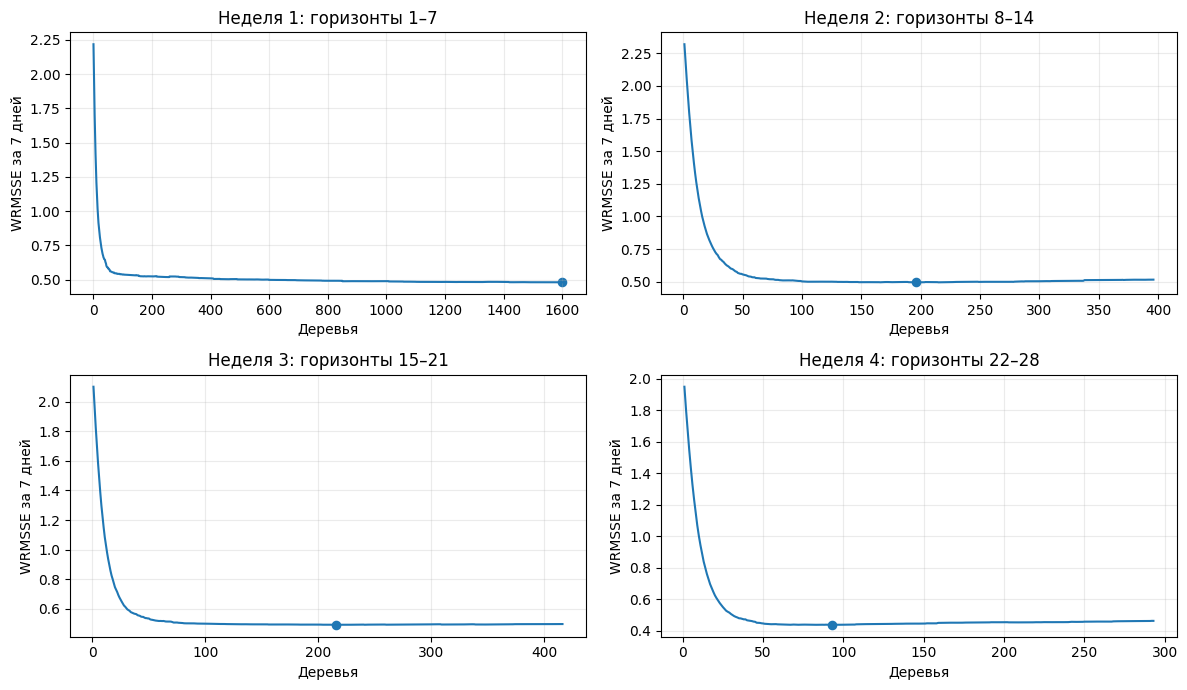

Checkpoint: 4/4 моделей; demand-planner_horizon_weeks_checkpoint.zip


In [25]:
curve_paths = [(spec, RESULT_DIR / spec["name"] / "learning_curve.csv") for spec in WEEK_SPECS]
if any(path.is_file() for _, path in curve_paths):
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, (spec, path) in zip(axes.flat, curve_paths):
        ax.set(
            title=f"Неделя {spec['week']}: горизонты {spec['horizon_start']}–{spec['horizon_end']}",
            xlabel="Деревья",
            ylabel="WRMSSE за 7 дней",
        )
        if path.is_file():
            curve = pd.read_csv(path)
            protocol = json.loads((path.parent / "protocol.json").read_text())
            ax.plot(np.arange(1, len(curve) + 1), curve["WRMSSE_week"])
            ax.scatter(protocol["best_iteration"], protocol["metrics"]["WRMSSE_7d"], s=35)
            ax.grid(alpha=0.25)
        else:
            ax.text(0.5, 0.5, "Ещё не обучена", ha="center", va="center", transform=ax.transAxes)
    fig.tight_layout()
    fig.savefig(RESULT_DIR / "week_learning_curves.png", dpi=150)
    plt.show()
    plt.close(fig)
    export_week_checkpoint()

## Результат и дополнительная проверка первой недели

Четыре модели дали общий исторический WRMSSE **0.495382**. Выбранные деревья:
**1598, 196, 216, 93**. Первая модель достигла лимита 1600.

В отдельном запуске предел первой недели поднят до 3200. Лучший результат —
**2076 деревьев**, недельный WRMSSE **0.476348** против **0.480606**. После замены
только первой недели полный WRMSSE стал **0.494257**.

Сохранённые выводы выше относятся к исходным четырём обучениям с лимитом 1600.
Протокол дополнительного запуска лежит в
[результатах первой недели](../results/m5_wrmsse/lgbm_horizon_week1_trial9_52x28_3200_v1).
Ансамбль моделей с обновлёнными прогнозами проверяется в [ноутбуке 09](09_horizon_ensemble.ipynb).

### Документация

- [LightGBM 4.6.0: train и пользовательская метрика](https://lightgbm.readthedocs.io/en/v4.6.0/pythonapi/lightgbm.train.html)
- [LightGBM 4.6.0: early stopping](https://lightgbm.readthedocs.io/en/v4.6.0/pythonapi/lightgbm.early_stopping.html)
- [Kaggle: сохранённые версии и окружение](https://www.kaggle.com/docs/notebooks)
- [Kaggle: одновременные batch-сессии и управление запусками](https://www.kaggle.com/docs/efficient-gpu-usage)